# Importing Neseccary Library

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Dataset

In [27]:
data = pd.read_csv('flipkart_com-ecommerce_sample.csv')
data.head()


,uniq_id,crawl_timestamp,product_url,product_name,product_category_tree,pid,retail_price,discounted_price,image,is_FK_Advantage_product,description,product_rating,overall_rating,brand,product_specifications
0,c2d766ca982eca8304150849735ffef9,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2FF9KEDEFGF,999.0,379.0,"[""http://img5a.flixcart.com/image/short/u/4/a/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
1,7f7036a6d550aaa89d34c77bd39a5e48,2016-03-25 22:59:23 +0000,http://www.flipkart.com/fabhomedecor-fabric-do...,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",SBEEH3QGU7MFYJFY,32157.0,22646.0,"[""http://img6a.flixcart.com/image/sofa-bed/j/f...",False,FabHomeDecor Fabric Double Sofa Bed (Finish Co...,No rating available,No rating available,FabHomeDecor,"{""product_specification""=>[{""key""=>""Installati..."
2,f449ec65dcbc041b6ae5e6a32717d01b,2016-03-25 22:59:23 +0000,http://www.flipkart.com/aw-bellies/p/itmeh4grg...,AW Bellies,"[""Footwear >> Women's Footwear >> Ballerinas >...",SHOEH4GRSUBJGZXE,999.0,499.0,"[""http://img5a.flixcart.com/image/shoe/7/z/z/r...",False,Key Features of AW Bellies Sandals Wedges Heel...,No rating available,No rating available,AW,"{""product_specification""=>[{""key""=>""Ideal For""..."
3,0973b37acd0c664e3de26e97e5571454,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2F6HUZMQ6SJ,699.0,267.0,"[""http://img5a.flixcart.com/image/short/6/2/h/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,2016-03-25 22:59:23 +0000,http://www.flipkart.com/sicons-all-purpose-arn...,Sicons All Purpose Arnica Dog Shampoo,"[""Pet Supplies >> Grooming >> Skin & Coat Care...",PSOEH3ZYDMSYARJ5,220.0,210.0,"[""http://img5a.flixcart.com/image/pet-shampoo/...",False,Specifications of Sicons All Purpose Arnica Do...,No rating available,No rating available,Sicons,"{""product_specification""=>[{""key""=>""Pet Type"",..."


# Data Preprocessing

In [28]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   uniq_id                  20000 non-null  object 
 1   crawl_timestamp          20000 non-null  object 
 2   product_url              20000 non-null  object 
 3   product_name             20000 non-null  object 
 4   product_category_tree    20000 non-null  object 
 5   pid                      20000 non-null  object 
 6   retail_price             19922 non-null  float64
 7   discounted_price         19922 non-null  float64
 8   image                    19997 non-null  object 
 9   is_FK_Advantage_product  20000 non-null  bool   
 10  description              19998 non-null  object 
 11  product_rating           20000 non-null  object 
 12  overall_rating           20000 non-null  object 
 13  brand                    14136 non-null  object 
 14  product_specifications

In [29]:
data.describe()

,retail_price,discounted_price
count,19922.000000,19922.000000
mean,2979.206104,1973.401767
std,9009.639341,7333.586040
min,35.000000,35.000000
25%,666.000000,350.000000
50%,1040.000000,550.000000
75%,1999.000000,999.000000
max,571230.000000,571230.000000


In [30]:
data.isnull().sum()

,0
uniq_id,0
crawl_timestamp,0
product_url,0
product_name,0
product_category_tree,0
pid,0
retail_price,78
discounted_price,78
image,3
is_FK_Advantage_product,0


In [55]:
data['brand'] = data['brand'].fillna('Unknown')
data['product_specifications'] = data['product_specifications'].fillna('Unknown')
data['image'] = data['image'].fillna('Not Available')
data['description'] = data['description'].fillna('Not Available')

data['retail_price'] = pd.to_numeric(data['retail_price'], errors='coerce')
data['discounted_price'] = pd.to_numeric(data['discounted_price'], errors='coerce')

In [32]:
data.isnull().sum()

,0
uniq_id,0
crawl_timestamp,0
product_url,0
product_name,0
product_category_tree,0
pid,0
retail_price,78
discounted_price,78
image,0
is_FK_Advantage_product,0


We have to balance our dataset , we have many null values present in this  datset so to balance the dataset we fill null values to Unknown.

In [33]:
data.duplicated().sum()

np.int64(0)

In [34]:
data['crawl_timestamp'] = pd.to_datetime(data['crawl_timestamp'])

In [35]:
data['product_rating'].value_counts()

,count
product_rating,
No rating available,18151
5,620
4,246
1,171
3,168
2,80
4.5,67
3.7,51
4.2,47


In [36]:
data['overall_rating'].value_counts()

,count
overall_rating,
No rating available,18151
5,620
4,246
1,171
3,168
2,80
4.5,67
3.7,51
4.2,47


In [37]:
data['product_rating'] = pd.to_numeric(
    data['product_rating'],
    errors='coerce'
)

data['overall_rating'] = pd.to_numeric(
    data['overall_rating'],
    errors='coerce'
)

In [38]:
data[['retail_price', 'discounted_price']].describe()

,retail_price,discounted_price
count,19922.000000,19922.000000
mean,2979.206104,1973.401767
std,9009.639341,7333.586040
min,35.000000,35.000000
25%,666.000000,350.000000
50%,1040.000000,550.000000
75%,1999.000000,999.000000
max,571230.000000,571230.000000


# Visualization

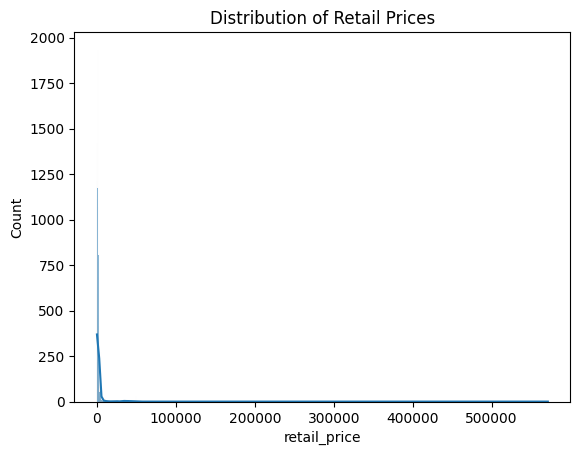

In [39]:
sns.histplot(data['retail_price'], kde=True)
plt.title('Distribution of Retail Prices')
plt.show()

### Insight: Distribution of Retail Prices
- **Extreme Skewness**: The distribution of retail prices is heavily right-skewed. The vast majority of listed products are priced on the lower end (under 10,000 INR).
- **High-Value Outliers**: There are extreme outliers reaching up to 571,230 INR (as confirmed by the descriptive statistics), indicating a few premium luxury goods or bulk product items in the dataset amidst mostly affordable consumer goods.

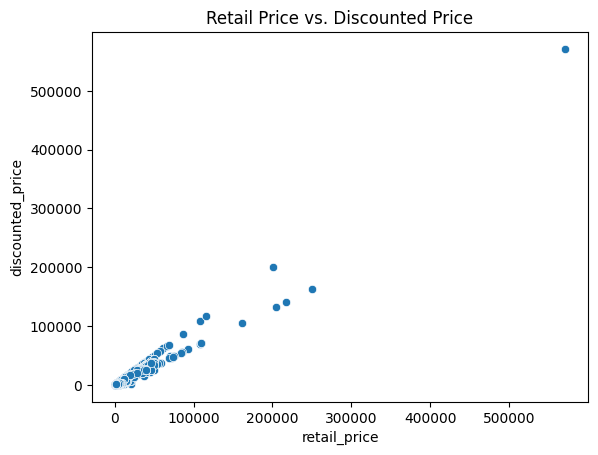

In [40]:
sns.scatterplot(x='retail_price', y='discounted_price', data=data)
plt.title('Retail Price vs. Discounted Price')
plt.show()


### Insight: Retail Price vs. Discounted Price
- **Strong Linear Correlation**: There is a highly positive linear relationship between the retail price and the discounted price, meaning that more expensive items generally maintain higher discounted prices.
- **Pricing Consistency**: Most data points cluster tightly near the diagonal line, indicating that while discounts are prevalent, the overall proportional pricing structure is consistently scaled.

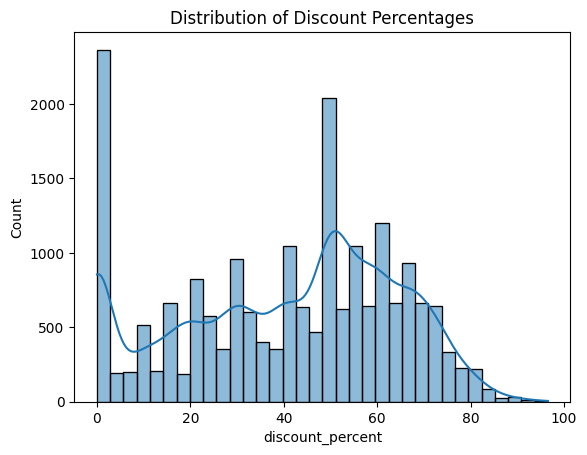

In [44]:
data['discount_percent'] = (
    (data['retail_price'] - data['discounted_price'])
    / data['retail_price']
) * 100
sns.histplot(data['discount_percent'], kde=True)
plt.title('Distribution of Discount Percentages')
plt.show()


### Insight: Distribution of Discount Percentages
- **Heavy Discount Strategy**: A significant spike is visible around 40% to 60% discounts, showing that the platform frequently relies on deep discounts to drive sales.
- **Zero-Discount Listings**: There is also a distinct group of products offered at exactly 0% discount (sold at full retail price), representing stable-priced or luxury goods where brand value is prioritized over promotional strategies.

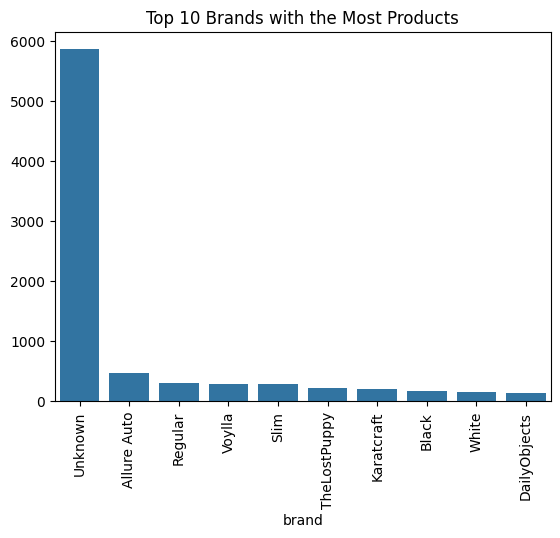

In [51]:
tops_brands = data['brand'].value_counts().head(10)


sns.barplot(x=tops_brands.index, y=tops_brands.values)
plt.title('Top 10 Brands with the Most Products')
plt.xticks(rotation=90)
plt.show()

**Insight** : visualization shows the top 10 brands based on the number of products listed in the dataset. The brand with the highest number of products has a significantly larger product presence compared with some of the other brands.

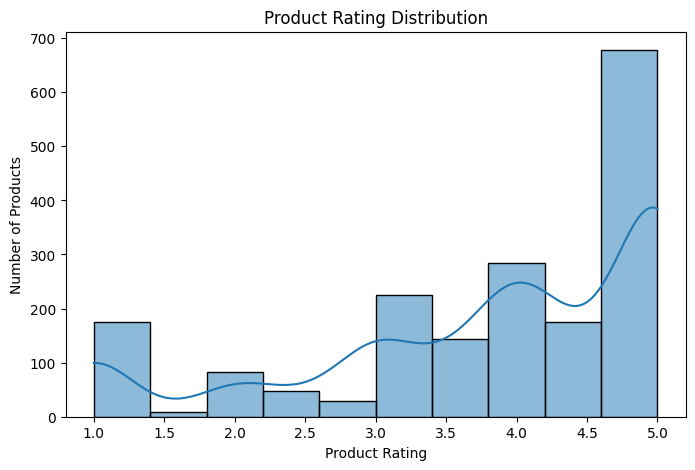

In [52]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x='product_rating',
    bins=10,
    kde=True
)

plt.title('Product Rating Distribution')
plt.xlabel('Product Rating')
plt.ylabel('Number of Products')

plt.show()

### Insight: Product Rating Distribution
- **Skewed Positivity**: For the products that actually have ratings, the distribution is skewed heavily towards highly positive scores (4.0 to 5.0 stars).
- **Rating Volatility**: While the vast majority of products do not have ratings (which were treated as NaN), the active customer feedback suggests overall satisfaction among buyers.

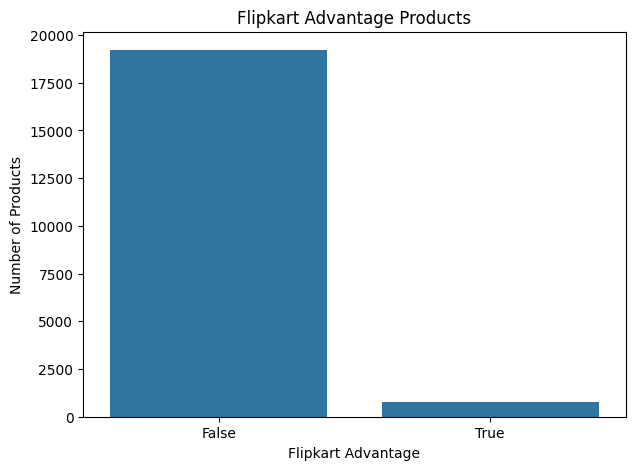

In [54]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x='is_FK_Advantage_product'
)

plt.title('Flipkart Advantage Products')
plt.xlabel('Flipkart Advantage')
plt.ylabel('Number of Products')

plt.show()

### Insight: Flipkart Advantage Products
- **Non-Advantage Dominance**: The vast majority of the listings do not fall under the 'Flipkart Advantage' banner.
- **Seller Diversity**: This highlights that the marketplace is heavily driven by third-party independent merchants rather than Flipkart-fulfilled, pre-verified partner logistics.

## Overall Project Summary & Executive Insights

Having explored and cleaned the Flipkart E-Commerce dataset, here are the strategic takeaways and project conclusions:

### 1. The Power of Promotional Pricing
- **Deep Discounting Culture**: Over half of the products on the platform feature discount rates between 40% and 60%. This points to an aggressive, promotional-driven sales strategy to attract value-seeking online shoppers.
- **Direct Correlation**: Despite the heavy markdowns, there is a strong linear correlation between the original retail price and the final sale price, meaning higher-end products maintain their relative value margins.

### 2. Marketplace vs. Managed Logistics
- **Third-Party Heavy**: The extreme imbalance in the `is_FK_Advantage_product` distribution reveals that the platform is primarily driven by independent third-party merchants rather than direct, Flipkart-fulfilled logistics. This supports a wide variety of brands and products but introduces variance in fulfillment speed and standards.

### 3. Feedback Loop Challenge (The Cold Start)
- **Low Review Volume**: Approximately 91% of products have no ratings available. This lack of active customer feedback might reflect standard catalog characteristics (e.g., massive niche items) or highlight the need to incentivize review submissions to improve customer trust.

### 4. Brand Dynamics
- **Long Tail Marketplace**: Apart from a few highly active brands, a massive portion of the inventory belongs to unknown, small, or unbranded labels (nearly 30%). This indicates a "long-tail" catalog structure where diversity of options is prioritized over a consolidated, highly curated selection of premium brand offerings.